In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import geopandas as gpd

In [ ]:
#Chargement du fond de carte de l'Île-de-France
gdf_iris = gpd.read_file("IDF_iris.geojson")
gdf_iris.head()

,typ_iris,insee_com,code_iris,nom_iris,dep,geo_point_2d,id,iris,nom_com,geometry
0,A,95051,950510105,Zone d'Activités,95,"[49.01802685248178, 2.1826610243984375]",IRIS____0000000950510105,0105,Beauchamp,"POLYGON ((2.18649 49.01053, 2.17345 49.01405, ..."
1,A,75112,751124811,Quinze-Vingts 11,75,"[48.844104305775815, 2.3753123018512237]",IRIS____0000000751124811,4811,Paris 12e Arrondissement,"POLYGON ((2.37114 48.84553, 2.37268 48.84568, ..."
2,D,75115,751156023,Jardin Citroën-Cévennes,75,"[48.840354178960965, 2.2752169001780462]",IRIS____0000000751156023,6023,Paris 15e Arrondissement,"POLYGON ((2.2746 48.84352, 2.27488 48.84342, 2..."
3,H,92062,920620101,Défense Nord,92,"[48.89129954997267, 2.23681617518544]",IRIS____0000000920620101,0101,Puteaux,"POLYGON ((2.24187 48.89066, 2.24236 48.8905, 2..."
4,H,92014,920140101,Les Bas Coquarts,92,"[48.78723129083917, 2.31362300907206]",IRIS____0000000920140101,0101,Bourg-la-Reine,"POLYGON ((2.31047 48.78489, 2.3097 48.7849, 2...."


In [14]:
#Récupération du tracé de la Ligne 14 (site IDFM)
ligne_14 = gpd.read_file("/Users/borhane/Documents/2A ENSAE/Projet Python 2A/projet_python_2a_ensae/traces-des-lignes-de-transport-en-commun-idfm-2.geojson")
ligne_14.head()

#On sélectionne la zone d'étude correspondant à la commune de Saint-Ouen (code INSEE 93070)
col_insee = 'insee_com' if 'insee_com' in gdf_iris.columns else 'depcom'
zone_etude = gdf_iris[gdf_iris[col_insee].astype(str) == '93070'] #Je force ici à convertir en str pour éviter les problèmes de type de données (les codes iNSEE sont lus comme des int ce qui pose problème)

# Vérifier et convertir si nécessaire le système de coordonnées de la ligne 14 pour qu'il corresponde à celui de la zone d'étude
if ligne_14.crs != zone_etude.crs:
    ligne_14 = ligne_14.to_crs(zone_etude.crs)

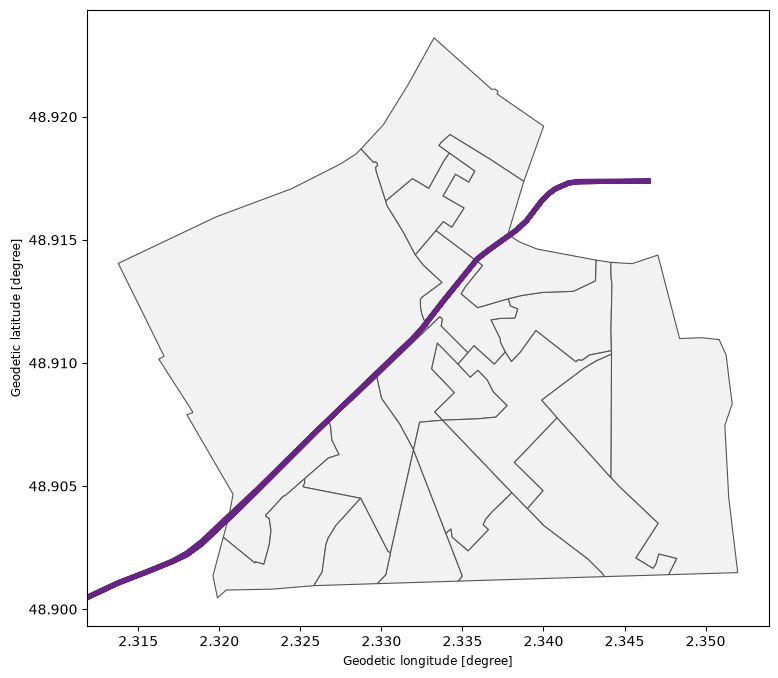

In [17]:
# Visualisation de la zone d'étude et de la ligne 14
fig, ax = plt.subplots(figsize=(10, 8))

zone_etude.plot(
    ax=ax,
    color="#f2f2f2",
    edgecolor="#555555",
    linewidth=0.8,
    label="Quartiers (IRIS)"
)
ligne_14.plot(
    ax=ax,
    color="#662483",
    linewidth=3.5,
    label="Ligne 14"
)

# Récupérer les limites géographiques (bords min et max) de Saint-Ouen
minx, miny, maxx, maxy = zone_etude.total_bounds #On récupère les limites géographiques de la zone d'étude (Saint-Ouen) pour ajuster le zoom du graphique (longitude et latitude)

# Ajouter une petite marge (ex: 10% autour) pour que les tracés ne touchent pas les bords du cadre
marge_x = (maxx - minx) * 0.05
marge_y = (maxy - miny) * 0.05

# Appliquer le zoom sur les axes du graphique
ax.set_xlim(minx - marge_x, maxx + marge_x)
ax.set_ylim(miny - marge_y, maxy + marge_y)

plt.show()